<a href="https://colab.research.google.com/github/ReshmaShi/MAIN-PROJECT-PYTHON/blob/main/KickstarterMainProj.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ***Kickstarter Funding Trends & Success Analysis***

# **Objective / Problem Statement**

The objective of this project is to analyze Kickstarter project data to understand the factors that influence project success and identify meaningful patterns and trends.

*To clean, transform, and preprocess the Kickstarter dataset for analysis.

*To perform Exploratory Data Analysis (EDA) and identify important patterns and trends.

*To analyze project categories, countries, goals, pledged amounts, backers, and project outcomes.

*To create meaningful visualizations that clearly communicate the findings.

*To identify factors associated with successful and unsuccessful Kickstarter projects.

*To provide actionable insights and recommendations based on the analysis.





# **Outcome**

The project helps identify important patterns in Kickstarter campaigns, including successful and unsuccessful projects, popular categories, country-wise trends, funding patterns, and the relationship between project goals, pledged amounts, and backers.

The analysis provides data-driven insights that can help project creators understand factors that may contribute to a successful crowdfunding campaign.

# **Domain**

Crowdfunding / Finance / E-commerce

# **Dataset Information**

Dataset Name: Kickstarter Projects Dataset

Source: Maven Analytics Data Playground – Kickstarter Projects

Source Link:
https://mavenanalytics.io/data-playground/kickstarter-projects

Year / Timeline:
The dataset contains Kickstarter projects launched between 2016 and 2018.

# **Dataset Column / Feature Description**
* **ID**  – Unique identification number assigned to each Kickstarter project.

* **Name** – Name or title of the Kickstarter project.

* **Category** – Specific category to which the project belongs, such as Product Design, Music, Games, Film & Video, etc.

* **Sub Category** – Broad category grouping of the project.

* **Country** – Country from which the Kickstarter project was launched.

* **Launched** – Date and time when the Kickstarter campaign was launched.

* **Deadline** – Date by which the Kickstarter campaign ends.

* **Goal** – Amount of money the project creator aimed to raise.

* **Pledged** – Amount of money pledged by backers to the project.

* **State** – Final status of the Kickstarter project, such as successful, failed, live, canceled, or suspended.

* **Backers**  – Number of people who financially supported the project.


In [ ]:
#Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#import dataset from github
df = pd.read_csv("https://raw.githubusercontent.com/ReshmaShi/MAIN-PROJECT-PYTHON/main/Kickstarter%20Success%20%5E0%20Failure%20Analytics%20%282016%E2%80%932018%29%20%E2%AD%90.csv")

df.head()

,ID,Name,Category,Subcategory,Country,Launched,Deadline,Goal,Pledged,Backers,State
0,1226985550,New Beginnings,Music,R&B,United States,02-11-2015 05:59,01-01-2016,7500,410,7,Failed
1,1779611174,iCause: the app that connects you to cause eve...,Technology,Web,United States,02-11-2015 10:35,01-01-2016,20000,1653,10,Failed
2,99020170,Vortex - Kinetic Toothbrush (Canceled),Technology,Technology,United States,02-11-2015 12:22,01-01-2016,67000,328,24,Canceled
3,181855778,DEADLIFT,Fashion,Apparel,United States,02-11-2015 13:59,01-01-2016,10000,510,7,Failed
4,2035759640,DAWG-E'z,Food,Spaces,United States,02-11-2015 16:46,01-01-2016,75000,1,1,Failed


In [ ]:
df.tail()

,ID,Name,Category,Subcategory,Country,Launched,Deadline,Goal,Pledged,Backers,State
113265,1486845240,Americas Got Talent - Serious MAK,Music,Hip-Hop,United States,02-01-2018 14:13,16-01-2018,500,0,0,Live
113266,974738310,EVO Planner: The World's First Personalized Fl...,Design,Product Design,United States,02-01-2018 14:15,09-02-2018,15000,269,8,Live
113267,2106246194,"Help save La Gattara, Arizona's first Cat Cafe!",Food,Food,United States,02-01-2018 14:17,16-01-2018,10000,165,3,Live
113268,1830173355,Digital Dagger Coin,Art,Art,United States,02-01-2018 14:38,01-02-2018,650,7,1,Live
113269,1339173863,Spirits of the Forest,Games,Tabletop Games,Spain,02-01-2018 15:02,26-01-2018,24274,4483,82,Live


In [ ]:
#Information of dataframe
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 113270 entries, 0 to 113269
Data columns (total 11 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   ID           113270 non-null  int64 
 1   Name         113270 non-null  object
 2   Category     113270 non-null  object
 3   Subcategory  113270 non-null  object
 4   Country      113270 non-null  object
 5   Launched     113270 non-null  object
 6   Deadline     113270 non-null  object
 7   Goal         113270 non-null  int64 
 8   Pledged      113270 non-null  int64 
 9   Backers      113270 non-null  int64 
 10  State        113270 non-null  object
dtypes: int64(4), object(7)
memory usage: 9.5+ MB


In [ ]:
df.describe()

,ID,Goal,Pledged,Backers
count,1.132700e+05,1.132700e+05,1.132700e+05,113270.000000
mean,1.074841e+09,5.443830e+04,1.159474e+04,125.043074
std,6.184757e+08,1.291572e+06,1.033106e+05,910.159108
min,1.852000e+04,0.000000e+00,0.000000e+00,0.000000
25%,5.417808e+08,2.000000e+03,2.500000e+01,2.000000
50%,1.075026e+09,6.385000e+03,5.390000e+02,11.000000
75%,1.607900e+09,2.000000e+04,4.236000e+03,60.000000
max,2.147448e+09,1.073699e+08,1.277984e+07,154926.000000


In [ ]:
#Describing columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,113270.0,1.074841e+09,6.184757e+08,18520.0,5.417808e+08,1.075026e+09,1.607900e+09,2.147448e+09
Goal,113270.0,5.443830e+04,1.291572e+06,0.0,2.000000e+03,6.385000e+03,2.000000e+04,1.073699e+08
Pledged,113270.0,1.159474e+04,1.033106e+05,0.0,2.500000e+01,5.390000e+02,4.236000e+03,1.277984e+07
Backers,113270.0,1.250431e+02,9.101591e+02,0.0,2.000000e+00,1.100000e+01,6.000000e+01,1.549260e+05


In [ ]:
#Describing object columns
df.describe(include="object").T

,count,unique,top,freq
Name,113270,112559,#NAME?,12
Category,113270,15,Games,14224
Subcategory,113270,159,Product Design,9436
Country,113270,22,United States,73942
Launched,113270,104778,20-06-2017 16:00,15
Deadline,113270,793,01-12-2017,356
State,113270,5,Failed,58184



# **Step 2 – Data Cleaning and Pre-processing**

1. Data Type Conversion

Converted the launched and deadline columns to datetime format for date-based analysis.

2. Feature Creation

Created a new column, duration, to calculate the number of days between the campaign launch date and deadline and created a column called funding percentage.

3. Missing Values and Duplicates

Checked the dataset and confirmed that there were no missing (null) values or duplicate records

4. Category-wise State Percentage

Calculated the percentage distribution of campaign outcomes within each category to compare successful, failed, and other campaign states.

5. Filtering and Aggregating Data

Filtered the dataset based on specific conditions to examine campaign outcomes and pledged amounts. Aggregated data by category and state to summarize campaign counts and compare outcome distributions across categories.

In [ ]:
#checking nullvalue in dataframe
df.isnull().sum()

,0
ID,0
Name,0
Category,0
Subcategory,0
Country,0
Launched,0
Deadline,0
Goal,0
Pledged,0
Backers,0


In [ ]:
#CHECKING DUPLICATES
df.duplicated().sum()

np.int64(0)

In [ ]:
#Count the number of projects in each state
df["State"].value_counts()

,count
State,
Failed,58184
Successful,38167
Canceled,13398
Live,2798
Suspended,723


In [ ]:
#count the number of projjects by category
df["Category"].value_counts()

,count
Category,
Games,14224
Technology,13686
Film & Video,12896
Design,12242
Publishing,11284
Music,10667
Fashion,8702
Art,7808
Food,7360


In [ ]:
#Count the number of projects in each country
df["Country"].value_counts()

,count
Country,
United States,73942
United Kingdom,12321
Canada,5713
Australia,3262
Germany,2950
Italy,2285
France,2138
Spain,1800
Mexico,1752


In [ ]:

df.head()


,ID,Name,Category,Subcategory,Country,Launched,Deadline,Goal,Pledged,Backers,State
0,1226985550,New Beginnings,Music,R&B,United States,02-11-2015 05:59,01-01-2016,7500,410,7,Failed
1,1779611174,iCause: the app that connects you to cause eve...,Technology,Web,United States,02-11-2015 10:35,01-01-2016,20000,1653,10,Failed
2,99020170,Vortex - Kinetic Toothbrush (Canceled),Technology,Technology,United States,02-11-2015 12:22,01-01-2016,67000,328,24,Canceled
3,181855778,DEADLIFT,Fashion,Apparel,United States,02-11-2015 13:59,01-01-2016,10000,510,7,Failed
4,2035759640,DAWG-E'z,Food,Spaces,United States,02-11-2015 16:46,01-01-2016,75000,1,1,Failed


In [ ]:
#ROUND MY VALUES
df.drop(columns=["ID"]).describe().round(0).T.apply(lambda x: x.map('{:,.0f}'.format))


,count,mean,std,min,25%,50%,75%,max
Goal,"113,270","54,438","1,291,572",0,"2,000","6,385","20,000","107,369,868"
Pledged,"113,270","11,595","103,311",0,25,539,"4,236","12,779,843"
Backers,"113,270",125,910,0,2,11,60,"154,926"


In [ ]:
#duplicate values
df.duplicated().sum()


np.int64(0)

In [ ]:
#data type

df.dtypes

,0
ID,int64
Name,object
Category,object
Subcategory,object
Country,object
Launched,object
Deadline,object
Goal,int64
Pledged,int64
Backers,int64


In [ ]:
# Keep a copy before cleaning
df_clean = df.copy()


In [ ]:
#changing launched and deadline datatype
df_clean["Launched"] = pd.to_datetime(df_clean["Launched"], dayfirst=True, errors="coerce")
df_clean["Deadline"] = pd.to_datetime(df_clean["Deadline"], dayfirst=True, errors="coerce")

df_clean[["Launched", "Deadline"]].isnull().sum()

,0
Launched,0
Deadline,0


In [ ]:
#created new column called duration

df_clean["Duration"] = (df_clean["Deadline"] - df_clean["Launched"]).dt.days

df_clean[["Launched", "Deadline", "Duration"]].head()

,Launched,Deadline,Duration
0,2015-11-02 05:59:00,2016-01-01,59
1,2015-11-02 10:35:00,2016-01-01,59
2,2015-11-02 12:22:00,2016-01-01,59
3,2015-11-02 13:59:00,2016-01-01,59
4,2015-11-02 16:46:00,2016-01-01,59


In [ ]:
#CHECKING INVALID DURATION VALUES
df_clean[df_clean["Duration"] < 0]


,ID,Name,Category,Subcategory,Country,Launched,Deadline,Goal,Pledged,Backers,State,Duration


In [ ]:
# Checking data types
df_clean.dtypes

,0
ID,int64
Name,object
Category,object
Subcategory,object
Country,object
Launched,datetime64[ns]
Deadline,datetime64[ns]
Goal,int64
Pledged,int64
Backers,int64


In [ ]:
#count by state
df_clean["State"].value_counts()

,count
State,
Failed,58184
Successful,38167
Canceled,13398
Live,2798
Suspended,723


In [ ]:
#percentage for each state
(df_clean["State"].value_counts(normalize=True) * 100).round(2)

,proportion
State,
Failed,51.37
Successful,33.70
Canceled,11.83
Live,2.47
Suspended,0.64


In [ ]:
df_clean[df_clean["Pledged"] == 0].head()

,ID,Name,Category,Subcategory,Country,Launched,Deadline,Goal,Pledged,Backers,State,Duration
7,2037298769,Pickles (Canceled),Food,Small Batch,Canada,2015-11-02 17:24:00,2016-01-01,7,0,0,Canceled,59
8,602026487,Healthy Restaurant Project X,Food,Restaurants,United States,2015-11-02 17:49:00,2016-01-01,1053000,0,0,Failed,59
13,416968319,Slapstick's T-Shirt Club For Men Funny Monthly...,Fashion,Apparel,United States,2015-11-02 21:37:00,2016-01-01,5000,0,0,Failed,59
16,722789723,Bloggers Meetup,Journalism,Journalism,Canada,2015-11-02 22:13:00,2016-01-01,1418,0,0,Failed,59
17,1491659558,Album/Video/Documentary and Tour Experience,Music,Hip-Hop,Sweden,2015-11-02 22:13:00,2016-01-01,2345,0,0,Failed,59


In [ ]:
#calculated how many care pledged amount is 0 or <0
(df_clean["Pledged"] <= 0).sum()

np.int64(14946)

In [ ]:
#checking state whether any campaign is sucessful when pledged amnt is 0 or < 0
df_clean[df_clean["Pledged"] == 0]["State"].value_counts()

,count
State,
Failed,10396
Canceled,3822
Live,548
Suspended,180


In [ ]:
#percentage of funding
(df_clean[df_clean["Pledged"] > 0]["State"].value_counts(normalize=True) * 100).round(2)

,proportion
State,
Failed,48.60
Successful,38.82
Canceled,9.74
Live,2.29
Suspended,0.55


In [ ]:
#creating column called funding percentage
df_clean["Funding_Percentage"] = ((df_clean["Pledged"] / df_clean["Goal"]).where(df_clean["Goal"] > 0) * 100).round(2)

df_clean.head()

,ID,Name,Category,Subcategory,Country,Launched,Deadline,Goal,Pledged,Backers,State,Duration,Funding_Percentage
0,1226985550,New Beginnings,Music,R&B,United States,2015-11-02 05:59:00,2016-01-01,7500,410,7,Failed,59,5.47
1,1779611174,iCause: the app that connects you to cause eve...,Technology,Web,United States,2015-11-02 10:35:00,2016-01-01,20000,1653,10,Failed,59,8.26
2,99020170,Vortex - Kinetic Toothbrush (Canceled),Technology,Technology,United States,2015-11-02 12:22:00,2016-01-01,67000,328,24,Canceled,59,0.49
3,181855778,DEADLIFT,Fashion,Apparel,United States,2015-11-02 13:59:00,2016-01-01,10000,510,7,Failed,59,5.10
4,2035759640,DAWG-E'z,Food,Spaces,United States,2015-11-02 16:46:00,2016-01-01,75000,1,1,Failed,59,0.00


In [ ]:
df_clean[df_clean["Goal"] <= 0]


,ID,Name,Category,Subcategory,Country,Launched,Deadline,Goal,Pledged,Backers,State,Duration,Funding_Percentage
54614,1379346088,Bug's Big Adventure: Mexico Edition,Art,Art,Mexico,2016-11-11 16:30:00,2016-11-12,0,16,7,Successful,0,NaN


In [ ]:
(df_clean["Goal"]<=0).sum()

np.int64(1)

In [ ]:
#goal achved
df_clean['Goal_Achieved'] = df_clean['Pledged'] >= df_clean['Goal']

goal_achievement = df_clean.groupby('State')['Goal_Achieved'].mean() * 100

goal_achievement.round(2)


,Goal_Achieved
State,
Canceled,2.36
Failed,0.00
Live,15.76
Successful,100.00
Suspended,18.12


In [ ]:
#
df_clean.groupby("State")["Goal"].median()

,Goal
State,
Canceled,10000.0
Failed,8000.0
Live,6523.5
Successful,4000.0
Suspended,8073.0


In [ ]:
category_state_count = pd.crosstab(df_clean["Category"],df_clean["State"])
category_state_count["Total"] = category_state_count.sum(axis=1)

category_state_count

State,Canceled,Failed,Live,Successful,Suspended,Total
Category,,,,,,
Art,680,3845,194,3050,39,7808
Comics,305,1210,76,2366,5,3962
Crafts,368,2172,76,826,28,3470
Dance,48,290,18,483,2,841
Design,1906,5395,305,4526,110,12242
Fashion,1034,5218,250,2151,49,8702
Film & Video,1357,6722,332,4437,48,12896
Food,676,4887,183,1560,54,7360
Games,2517,5781,287,5557,82,14224


In [ ]:
#median number of backers for each state
median_backers = df_clean.groupby('State')['Backers'].median()
median_backers


,Backers
State,
Canceled,3.0
Failed,3.0
Live,5.0
Successful,85.0
Suspended,4.0


# **Identift outliers**

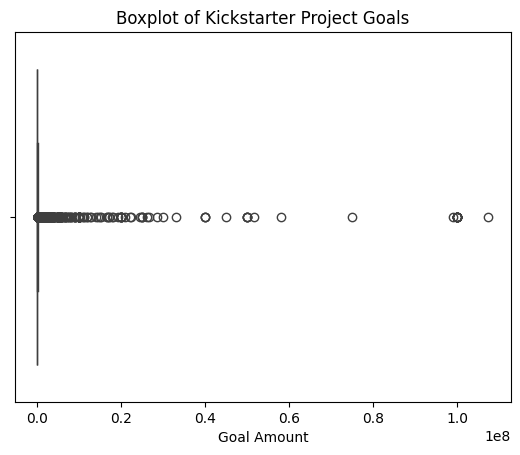

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x=df_clean["Goal"])
plt.title("Boxplot of Kickstarter Project Goals")
plt.xlabel("Goal Amount")
plt.show()

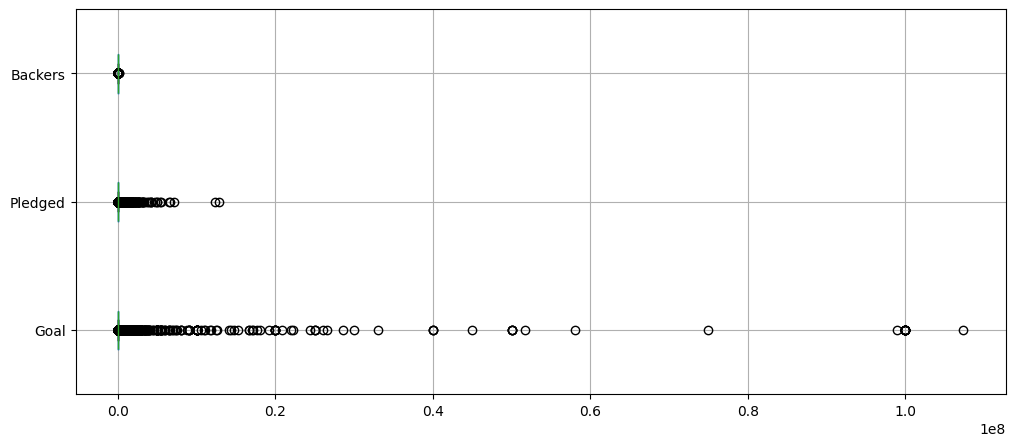

In [ ]:
numerical_columns = ["Goal", "Pledged", "Backers"]
df_clean.boxplot(column=numerical_columns,vert=False,figsize=(12, 5))
plt.show()

In [ ]:
pd.options.display.float_format = '{:,.2f}'.format
df_clean["Goal"].describe()


,Goal
count,"113,270.00"
mean,"54,438.30"
std,"1,291,571.52"
min,0.00
25%,"2,000.00"
50%,"6,385.00"
75%,"20,000.00"
max,"107,369,868.00"


In [ ]:
Q1 = df_clean["Goal"].quantile(0.25)
Q3 = df_clean["Goal"].quantile(0.75)

IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR

print("Upper limit:", upper_limit)

Upper limit: 47000.0


In [ ]:
goal_outliers = df_clean[df_clean["Goal"] > 47000]

print("Number of potential outliers:", len(goal_outliers))

Number of potential outliers: 12660


In [ ]:
goal_outliers[["Goal", "Pledged", "State", "Category"]].sort_values(by="Goal", ascending=False).head(10)

,Goal,Pledged,State,Category
62604,107369868,39,Failed,Film & Video
56391,100000000,1,Failed,Journalism
98216,100000000,59,Failed,Art
33206,100000000,14,Failed,Film & Video
30214,100000000,0,Canceled,Publishing
9356,100000000,2,Failed,Technology
94512,100000000,1,Failed,Film & Video
94511,100000000,0,Failed,Film & Video
20955,100000000,115,Failed,Art
59491,100000000,0,Failed,Film & Video


In [ ]:
Q1 = df_clean["Pledged"].quantile(0.25)
Q3 = df_clean["Pledged"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

pledged_outliers = df_clean[(df_clean["Pledged"] < lower_limit) | (df_clean["Pledged"] > upper_limit)]

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Number of potential outliers:", len(pledged_outliers))

Lower limit: -6291.5
Upper limit: 10552.5
Number of potential outliers: 16218


In [ ]:
pledged_outliers[["Goal", "Pledged", "State", "Category"]].sort_values(
    by="Pledged", ascending=False
).head(10)

,Goal,Pledged,State,Category
29120,1000000,12779843,Successful,Design
56892,100000,12393140,Successful,Games
100496,40000,7072757,Successful,Games
36910,500000,6565783,Successful,Design
43626,15000,6465690,Successful,Design
23238,72843,5494493,Successful,Games
73305,50000,5333793,Successful,Technology
55553,20878,5020667,Successful,Design
83617,300000,5004495,Successful,Games
78544,21500,4729263,Successful,Design


In [ ]:
Q1 = df_clean["Backers"].quantile(0.25)
Q3 = df_clean["Backers"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

backers_outliers = df_clean[
    (df_clean["Backers"] < lower_limit) |
    (df_clean["Backers"] > upper_limit
  )]

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Number of potential outliers:", len(backers_outliers))

Lower limit: -85.0
Upper limit: 147.0
Number of potential outliers: 14820


In [ ]:
backers_outliers[["Goal", "Pledged", "Backers", "State", "Category"]].sort_values(by="Backers", ascending=False).head(10)

,Goal,Pledged,Backers,State,Category
43626,15000,6465690,154926,Successful,Design
50909,10000,3215680,85581,Successful,Games
29120,1000000,12779843,66673,Successful,Design
10995,10000,3246589,63758,Successful,Games
100496,40000,7072757,43733,Successful,Games
75300,100000,3999796,40642,Successful,Games
49766,10000,1022121,36863,Successful,Design
2038,31416,1731466,36781,Successful,Technology
51688,30000,1076940,35549,Successful,Technology
94996,10000,1865141,33720,Successful,Games


### Outlier Analysis — Backers

**Method:** Boxplot and IQR method.

**Upper outlier limit:** 147 backers.

**Potential outliers identified:** 14,820 projects.

**Observation:** Inspection of the 10 projects with the highest backer counts showed that all were successful projects with unusually high numbers of backers.

**Decision:** Retain these values because they may represent genuinely popular projects. Do not remove values solely because they are statistical outliers.

# **Check skewness**

In [ ]:
df_clean[["Goal", "Pledged", "Backers"]].skew().round(2)

,0
Goal,65.85
Pledged,54.11
Backers,67.78


In [ ]:
import numpy as np

df_clean["Goal_log"] = np.log1p(df_clean["Goal"])
df_clean["Pledged_log"] = np.log1p(df_clean["Pledged"])
df_clean["Backers_log"] = np.log1p(df_clean["Backers"])

df_clean[["Goal_log", "Pledged_log", "Backers_log"]].skew().round(2)

,0
Goal_log,-0.17
Pledged_log,-0.30
Backers_log,0.48


### Skewness Analysis and Transformation

**Objective:** To examine the distribution of numerical columns and reduce extreme skewness where useful.

**Columns analysed:** `Goal`, `Pledged`, and `Backers`.

**Method:** Calculated skewness using Pandas and applied the `np.log1p()` transformation to create separate transformed columns.

**Results:** Original skewness values were 65.85 for Goal, 54.11 for Pledged, and 67.78 for Backers. After transformation, the values became -0.17, -0.30, and 0.48, respectively.

**Conclusion:** The log transformation substantially reduced skewness. The original columns were retained, and the transformed columns were added for potential use in visualizations and further analysis.

In [ ]:
#avg pledge by state
df_clean.groupby("State")["Pledged"].mean().round(2)

,Pledged
State,
Canceled,"2,838.61"
Failed,"1,227.25"
Live,"5,871.26"
Successful,"30,968.22"
Suspended,"7,616.29"


### Average Pledged Amount by Campaign State

The average pledged amount was calculated for each campaign state using the groupby and mean functions. Successful campaigns had the highest average pledged amount (30,968.22), while failed campaigns had the lowest (1,227.25). Canceled campaigns averaged 2,838.61, live campaigns 5,871.26, and suspended campaigns 7,616.29. These findings indicate that successful campaigns generally received higher pledged amounts than failed campaigns.

In [ ]:
df_clean.groupby("State")["Backers"].mean().round(2)

,Backers
State,
Canceled,28.63
Failed,15.13
Live,68.12
Successful,331.01
Suspended,104.13


### Average Backers by Campaign State

The average number of backers was compared across Kickstarter campaign states. Successful campaigns had the highest average, at 331.01 backers, while failed campaigns had the lowest, at 15.13 backers.

**Insight:** Campaigns with more backers tended to be associated with successful outcomes. However, this comparison alone does not prove that having more backers causes a campaign to succeed.

In [ ]:
#avg goal by state
df_clean.groupby("State")["Goal"].mean().round(2)

,Goal
State,
Canceled,"81,517.24"
Failed,"74,174.63"
Live,"62,548.70"
Successful,"10,178.69"
Suspended,"269,405.33"


In [ ]:
#claculate sucess rate
category_state_count["Total"] = category_state_count[["Canceled", "Failed", "Live", "Successful", "Suspended"]].sum(axis=1)
success_rate = (category_state_count["Successful"] / category_state_count["Total"]) * 100
success_rate.sort_values(ascending=False)

,0
Category,
Comics,59.72
Dance,57.43
Theater,56.15
Music,42.89
Games,39.07
Art,39.06
Design,36.97
Film & Video,34.41
Photography,34.02


### Category-wise Success Rate Analysis

The success rate was calculated for each Kickstarter category by dividing the number of successful campaigns by the total number of campaigns in that category and multiplying by 100.

**Key findings:**
- Comics had the highest success rate at 59.72%.
- Dance and Theater followed, with 57.43% and 56.15%, respectively.
- Journalism had the lowest success rate at 17.95%, followed by Technology at 18.75%.

**Conclusion:** The success rate varied across Kickstarter categories. Comics, Dance, and Theater had comparatively higher success rates, while Journalism and Technology had lower success rates.

In [ ]:
df_clean["Goal_Range"] = pd.cut(
    df_clean["Goal"],
    bins=[0, 1000, 5000, 10000, 50000, float("inf")],
    labels=["0–1K", "1K–5K", "5K–10K", "10K–50K", "Above 50K"],include_lowest=True)

In [ ]:
goal_success_rate = (df_clean.groupby("Goal_Range", observed=True)["State"].apply(lambda x: (x == "Successful").mean() * 100).round(2))
goal_success_rate

,State
Goal_Range,
0–1K,49.71
1K–5K,38.81
5K–10K,33.32
10K–50K,26.53
Above 50K,10.29


### Goal Range vs Success Rate Analysis

Campaigns were grouped into five funding goal ranges, and the success rate was calculated for each group.

**Key findings:**
- Campaigns with goals between 0 and 1,000 had the highest success rate at 49.71%.
- The success rate decreased to 26.53% for goals between 10,000 and 50,000.
- Campaigns with goals above 50,000 had the lowest success rate at 10.29%.

**Conclusion:** In this dataset, campaigns with lower funding goals generally had higher success rates. Higher funding targets may be more difficult to achieve, although this analysis alone cannot establish the reason.

# **Stage 3 – Visualizations**

In [ ]:
df_clean.head(5)

,ID,Name,Category,Subcategory,Country,Launched,Deadline,Goal,Pledged,Backers,State,Duration,Funding_Percentage,Goal_Achieved,Goal_log,Pledged_log,Backers_log,Goal_Range
0,1226985550,New Beginnings,Music,R&B,United States,2015-11-02 05:59:00,2016-01-01,7500,410,7,Failed,59,5.47,False,8.92,6.02,2.08,5K–10K
1,1779611174,iCause: the app that connects you to cause eve...,Technology,Web,United States,2015-11-02 10:35:00,2016-01-01,20000,1653,10,Failed,59,8.26,False,9.90,7.41,2.40,10K–50K
2,99020170,Vortex - Kinetic Toothbrush (Canceled),Technology,Technology,United States,2015-11-02 12:22:00,2016-01-01,67000,328,24,Canceled,59,0.49,False,11.11,5.80,3.22,Above 50K
3,181855778,DEADLIFT,Fashion,Apparel,United States,2015-11-02 13:59:00,2016-01-01,10000,510,7,Failed,59,5.10,False,9.21,6.24,2.08,5K–10K
4,2035759640,DAWG-E'z,Food,Spaces,United States,2015-11-02 16:46:00,2016-01-01,75000,1,1,Failed,59,0.00,False,11.23,0.69,0.69,Above 50K


# **Univariate** **Analysis**

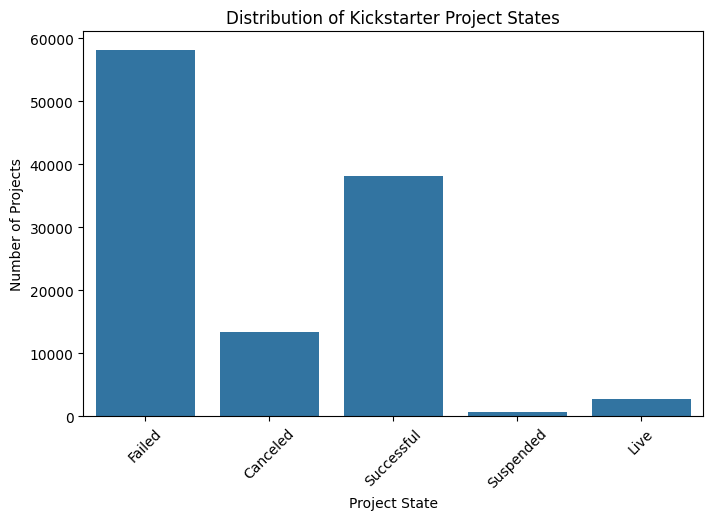

In [ ]:
#countplot counts the projects in each category
plt.figure(figsize=(8, 5))
sns.countplot(data=df_clean, x='State')
plt.title('Distribution of Kickstarter Project States')
plt.xlabel('Project State')
plt.ylabel('Number of Projects')
plt.xticks(rotation=45)
plt.show()


# **Interpretation: State Countplot**

- **Chart:** Shows the number of projects in each state.
- **Finding:** Failed projects have the highest count, followed by Successful projects.
- **Features used:** `State` column and project count, using `sns.countplot()`.
- **Business insight:** Helps us understand the overall distribution of project outcomes and investigate factors associated with success or failure.

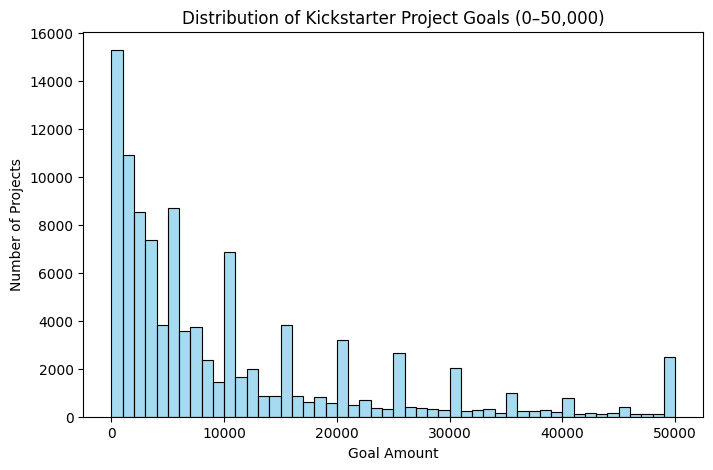

In [ ]:
#Histogram for goal

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x='Goal',
    bins=50,
    binrange=(0, 50000),
    color='skyblue',
    edgecolor='black'
)

plt.title('Distribution of Kickstarter Project Goals (0–50,000)')
plt.xlabel('Goal Amount')
plt.ylabel('Number of Projects')

plt.show()




## **Interpretation: Distribution of Kickstarter Project Goals**

- **Chart:** The histogram shows the distribution of funding goals set by Kickstarter campaigns.
- **Finding:** The height of each bar represents the number of projects within a particular goal-amount interval. This helps identify the goal ranges in which projects are concentrated.
- **Features used:** `Goal`, with 50 bins covering the range from 0 to 50,000.
- **Business insight:** Understanding the distribution of funding goals helps us identify common funding-target ranges and compare them with project success rates.

**Conclusion:** This histogram describes how project goals are distributed. Our separate goal-range success-rate analysis helps determine which goal ranges have higher success rates.

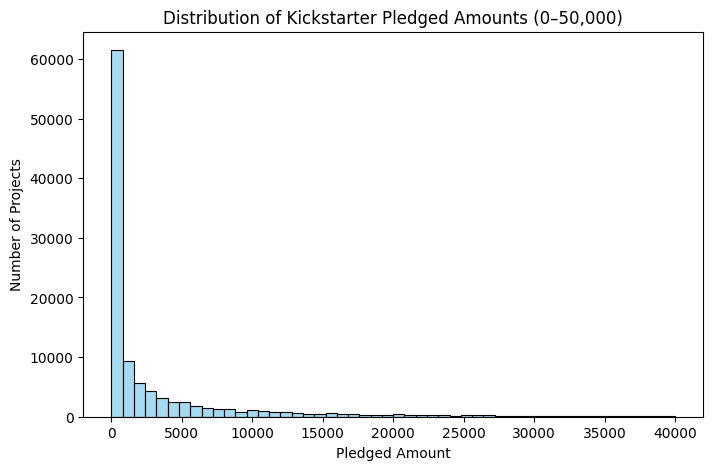

In [ ]:
#histogram for pledged

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x='Pledged',
    bins=50,
    binrange=(0,40000),
    color='skyblue',
    edgecolor='black'
)

plt.title('Distribution of Kickstarter Pledged Amounts (0–50,000)')
plt.xlabel('Pledged Amount')
plt.ylabel('Number of Projects')

plt.show()


### Interpretation: Distribution of Kickstarter Pledged Amounts

- **Chart:** Shows the distribution of money pledged to Kickstarter projects within the range of 0 to 40,000.
- **Finding:** The height of each bar represents the number of projects within that pledged-amount interval.
- **Features used:** `Pledged`, with 50 bins covering the range from 0 to 50,000.
- **Business insight:** Understanding how pledged amounts are distributed helps us investigate the relationship between funding received and project success.

**Note:** Projects with pledged amounts above 50,000 are not visible in this chart, but they remain in the dataset.

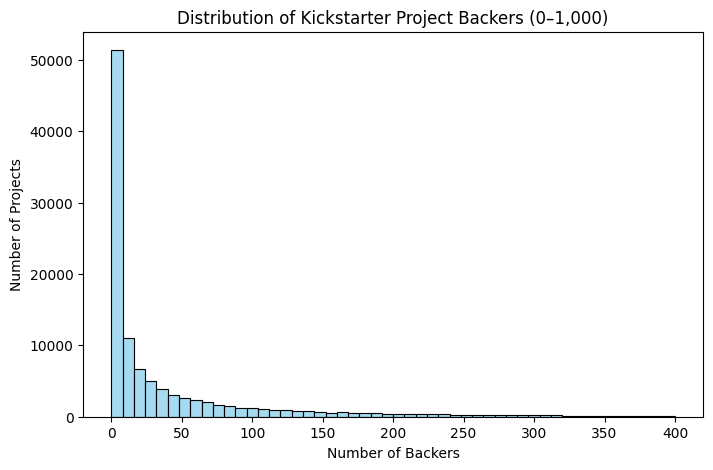

In [ ]:
#histogram for backers

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x='Backers',
    bins=50,
    binrange=(0, 400),
    color='skyblue',
    edgecolor='black'
)

plt.title('Distribution of Kickstarter Project Backers (0–1,000)')
plt.xlabel('Number of Backers')
plt.ylabel('Number of Projects')

plt.show()



### Interpretation: Distribution of Kickstarter Project Backers

- **Chart:** Shows the distribution of project backer counts from 0 to 400.
- **Finding:** Helps identify the backer-count ranges in which projects are concentrated.
- **Features used:** `Backers`, with 50 bins covering the selected range.
- **Business insight:** Understanding backer counts helps us investigate whether projects attracting more supporters tend to have higher success rates.

# **Bivariate visualisation:
# **Category vs Success Rate**

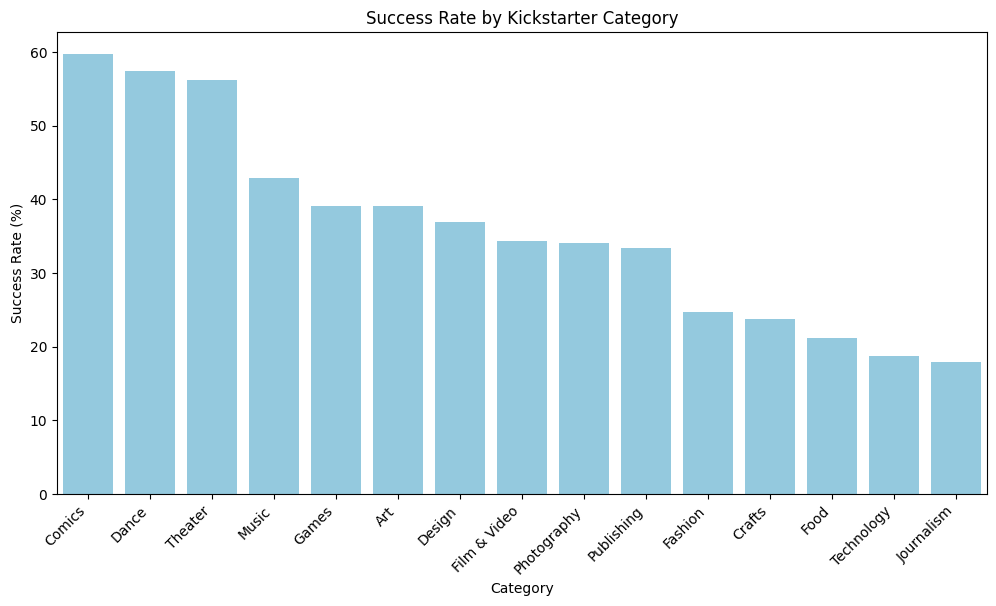

In [ ]:

plt.figure(figsize=(12, 6))

sns.barplot(
    x=success_rate.sort_values(ascending=False).index,
    y=success_rate.sort_values(ascending=False).values,
    color='skyblue'
)

plt.title('Success Rate by Kickstarter Category')
plt.xlabel('Category')
plt.ylabel('Success Rate (%)')
plt.xticks(rotation=45, ha='right')

plt.show()


### Interpretation: Success Rate by Kickstarter Category

- **Chart:** Compares the success rates of Kickstarter projects across different categories.
- **Finding:** Comics had the highest success rate (59.72%), while Journalism had the lowest (17.95%) in our earlier analysis.
- **Features used:** `Category` and `State`, using the calculated `success_rate` percentages.
- **Business insight:** Some categories have higher success rates than others. This information can help creators understand how project outcomes vary by category when planning their campaigns.

# **Goal Range vs Success Rate bar chart**

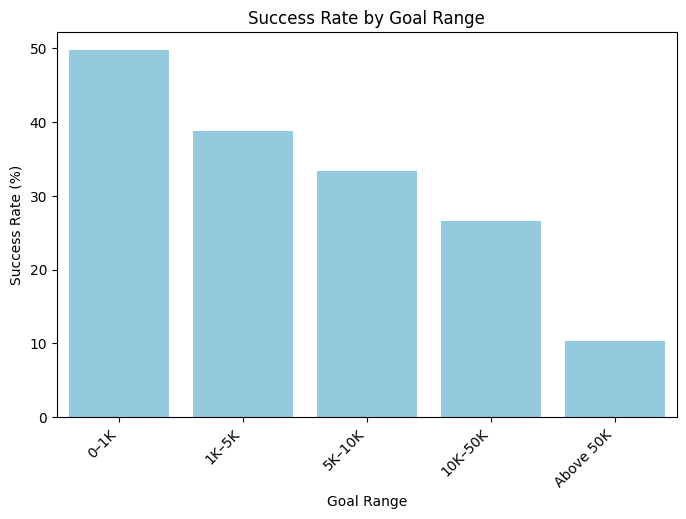

In [ ]:

plt.figure(figsize=(8, 5))

sns.barplot(
    x=goal_success_rate.index,
    y=goal_success_rate.values,
    color='skyblue'
)

plt.title('Success Rate by Goal Range')
plt.xlabel('Goal Range')
plt.ylabel('Success Rate (%)')
plt.xticks(rotation=45, ha='right')

plt.show()


### Interpretation: Success Rate by Goal Range

- **Chart:** Compares Kickstarter project success rates across different funding goal ranges.
- **Finding:** Projects with goals below 1,000 had the highest success rate (49.71%), while projects with goals above 50,000 had the lowest (10.29%) in our earlier analysis.
- **Features used:** `Goal_Range` and `State`, using the calculated `goal_success_rate` percentages.
- **Business insight:** Projects with lower funding targets had higher success rates in this dataset. Creators can consider their funding targets carefully, although a lower target does not guarantee success.

# **Goal vs Pledged Scatterplot**

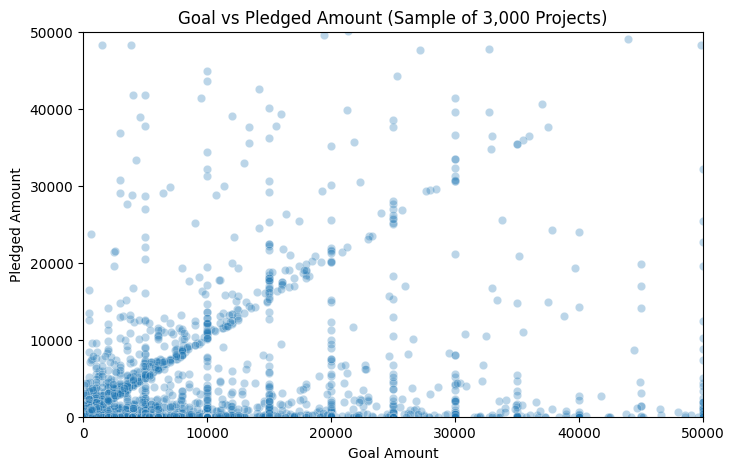

In [ ]:

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_clean.sample(n=3000, random_state=42),
    x='Goal',
    y='Pledged',
    alpha=0.3
)

plt.xlim(0, 50000)
plt.ylim(0, 50000)

plt.title('Goal vs Pledged Amount (Sample of 3,000 Projects)')
plt.xlabel('Goal Amount')
plt.ylabel('Pledged Amount')

plt.show()


### Interpretation: Goal vs Pledged Amount

- **Chart:** Shows the relationship between the funding goal and the amount pledged to Kickstarter projects.
- **Finding:** Each dot represents a project. The distribution of dots helps us observe how pledged amounts vary across different funding goals.
- **Features used:** `Goal` and `Pledged`.
- **Business insight:** Comparing funding goals with pledged amounts helps us understand whether projects are receiving funding in line with their targets and identify projects that may fall short of their goals.

**Note:** The chart focuses on amounts between 0 and 50,000. Projects outside this range are not displayed.

# **Correlation heatmap**

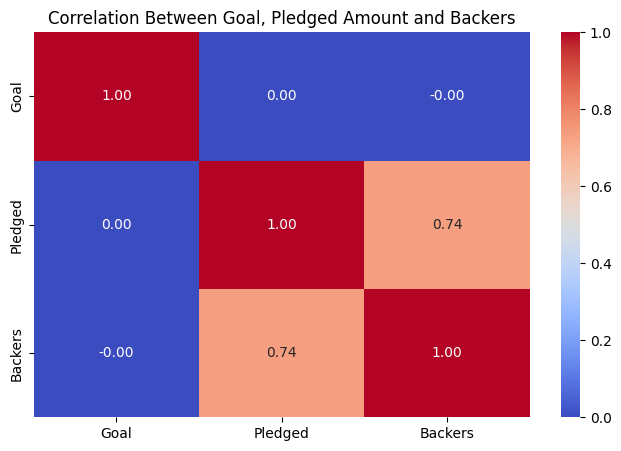

In [ ]:

plt.figure(figsize=(8, 5))

sns.heatmap(
    df_clean[['Goal', 'Pledged', 'Backers']].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Between Goal, Pledged Amount and Backers')
plt.show()


### Interpretation: Correlation Heatmap

- **Chart:** Shows the correlation between Goal, Pledged, and Backers.
- **Finding:** Pledged amount and number of backers have a strong positive correlation of 0.74. Goal has almost no linear correlation with either Pledged (0.00) or Backers (-0.00) in this dataset.
- **Features used:** `Goal`, `Pledged`, and `Backers`.
- **Business insight:** The results suggest that projects attracting more backers tend to receive more pledged money. However, the funding goal alone has almost no linear relationship with the amount pledged or number of backers in this analysis. Creators may benefit from understanding how audience support relates to fundraising, while recognizing that correlation does not prove causation or determine project success.



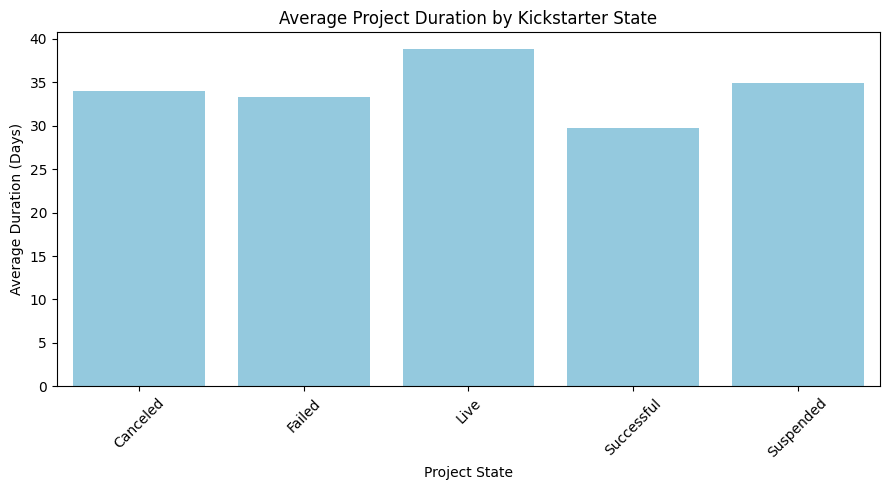

In [ ]:

avg_duration = df_clean.groupby('State')['Duration'].mean().round(1)

plt.figure(figsize=(9, 5))
sns.barplot(x=avg_duration.index, y=avg_duration.values, color='skyblue')

plt.title('Average Project Duration by Kickstarter State')
plt.xlabel('Project State')
plt.ylabel('Average Duration (Days)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


**Average Project Duration by Kickstarter State**
- **Chart**: Compares the average duration of Kickstarter projects across different project states.
- **Observation**: The average duration is relatively similar across states, with most values falling within approximately 30–40 days.
- **Features Used**: State, Duration
- **Business Insigh**t: Average project duration does not show a major difference across project outcomes in this dataset. Therefore, scheduled duration alone may not be a strong indicator of project success or failure.

# **Multivariate Analysis**


In [ ]:
category_goal_success = (
    df_clean.groupby(['Category', 'Goal_Range'], observed=True)['State']
    .apply(lambda x: (x == 'Successful').mean() * 100)
    .round(2)
    .reset_index(name='Success_Rate')
)

category_goal_success.head(10).T

,0,1,2,3,4,5,6,7,8,9
Category,Art,Art,Art,Art,Art,Comics,Comics,Comics,Comics,Comics
Goal_Range,0–1K,1K–5K,5K–10K,10K–50K,Above 50K,0–1K,1K–5K,5K–10K,10K–50K,Above 50K
Success_Rate,52.42,38.16,31.66,24.43,8.36,75.17,58.91,50.82,46.42,15.00


In [ ]:
category_goal_success.head(10)

,Category,Goal_Range,Success_Rate
0,Art,0–1K,52.42
1,Art,1K–5K,38.16
2,Art,5K–10K,31.66
3,Art,10K–50K,24.43
4,Art,Above 50K,8.36
5,Comics,0–1K,75.17
6,Comics,1K–5K,58.91
7,Comics,5K–10K,50.82
8,Comics,10K–50K,46.42
9,Comics,Above 50K,15.00


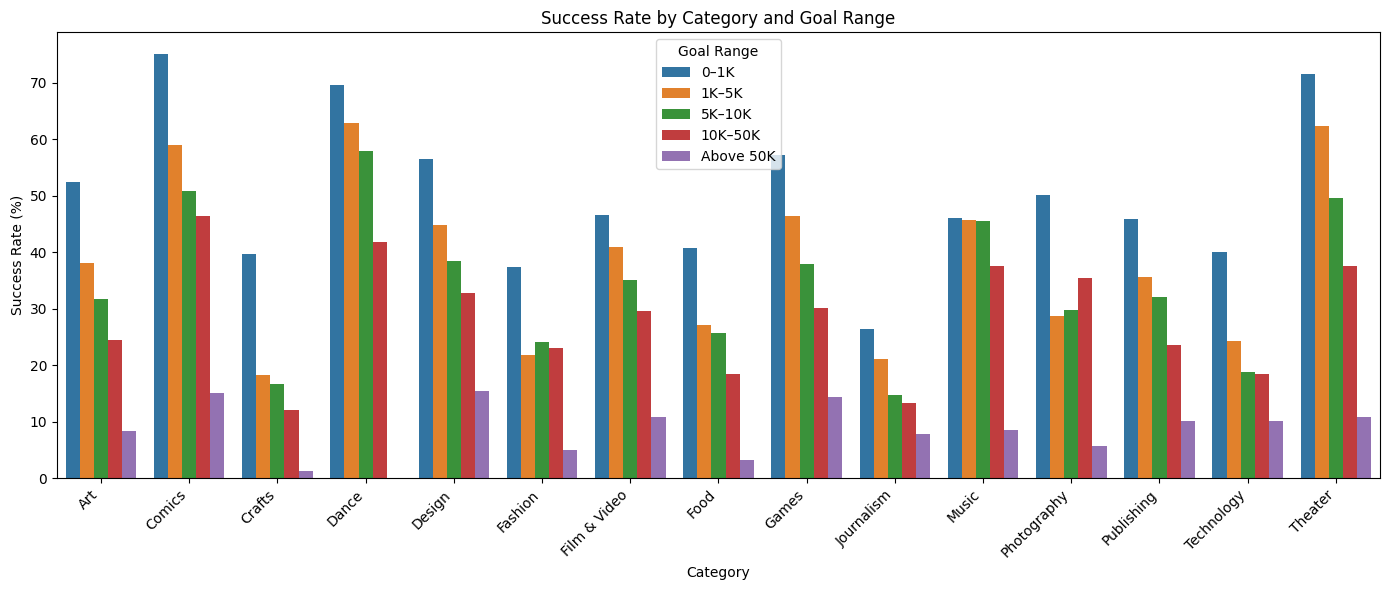

In [ ]:

plt.figure(figsize=(14, 6))

sns.barplot(
    data=category_goal_success,
    x='Category',
    y='Success_Rate',
    hue='Goal_Range'
)

plt.title('Success Rate by Category and Goal Range')
plt.xlabel('Category')
plt.ylabel('Success Rate (%)')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Goal Range')
plt.tight_layout()
plt.show()


### Interpretation: Success Rate by Category and Goal Range

- **Chart:** Compares Kickstarter success rates across project categories and funding goal ranges.
- **Finding:** Projects in the 0–1K goal range generally show higher success rates than projects with larger funding goals across the categories analysed.
- **Features used:** `Category`, `Goal_Range`, and `State` (used to calculate `Success_Rate`).
- **Business insight:** The analysis suggests that projects with lower funding targets tend to have higher success rates across categories. Creators can consider this pattern when setting realistic funding goals, although a lower target does not guarantee success.



In [ ]:
df_clean.to_csv('kickstarter_cleaned.csv', index=False)

In [ ]:
from google.colab import files
files.download('kickstarter_cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Dashboard**

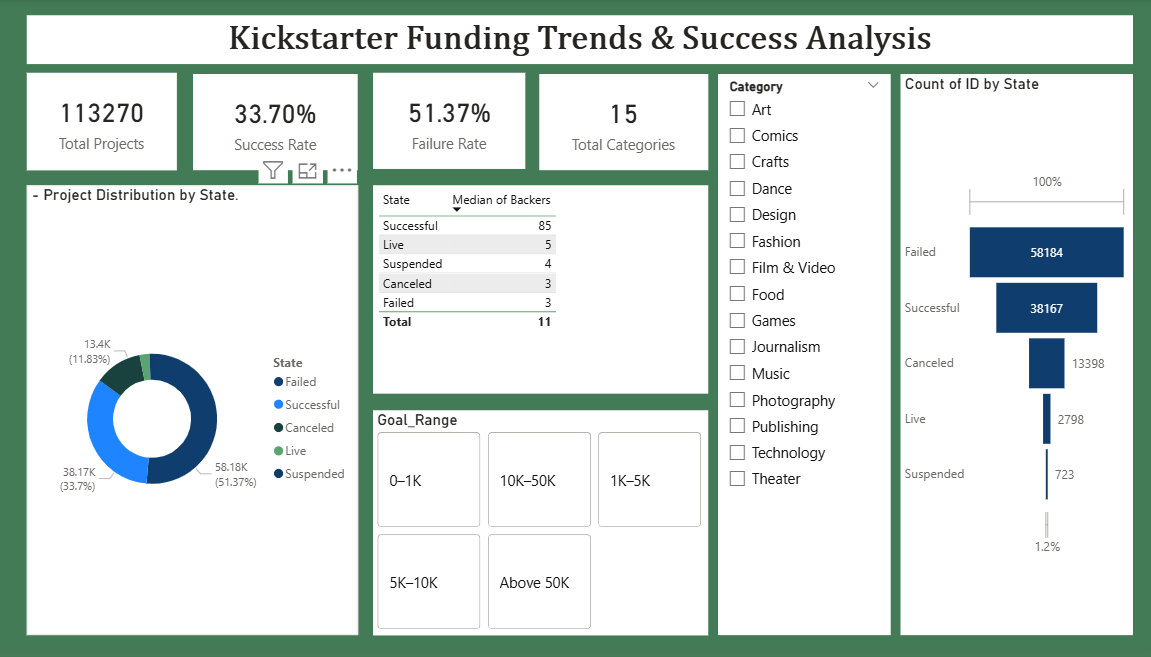

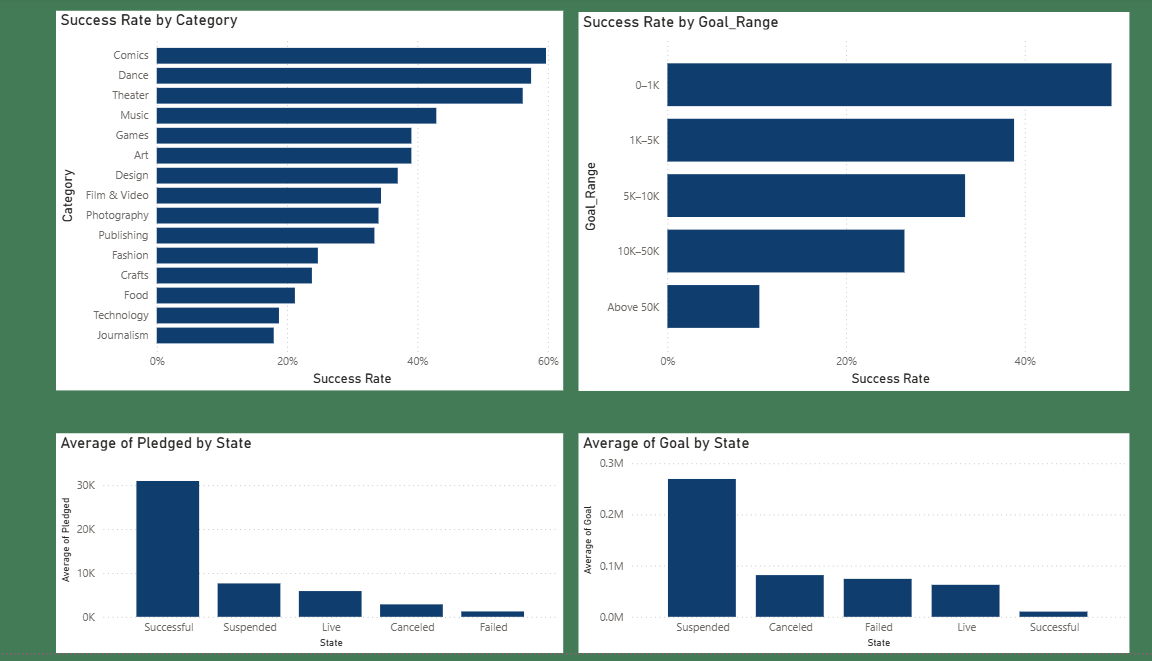

## **Final Overall Insights**

1. The dataset contained **113,270 projects and 17 columns** after preprocessing. Missing values were checked, duplicate records were checked and handled, and the launch and deadline columns were converted to datetime format.

2. Project state distribution showed that **51% of projects failed, 34% were successful, 12% were canceled, 2% were live, and 1% were suspended**. Failed projects formed the largest group in the dataset.

3. The dataset contained **15 categories, 159 subcategories, and 22 countries**. Games had the highest project count, with 14,224 projects. Product Design was the most frequent subcategory, with 9,436 projects.

4. Category-wise success rate analysis showed that **Comics had the highest success rate at 59.72%**, followed by Dance at 57.43% and Theater at 56.15%. Journalism had the lowest success rate at 17.95%, followed by Technology at 18.75%.

5. Funding goal range analysis showed that projects with goals of **0–1K had a success rate of 49.71%**, compared with 38.81% for 1K–5K, 33.32% for 5K–10K, 26.53% for 10K–50K, and 10.29% for goals above 50K. Success rates generally decreased as the funding goal range increased.

6. The distribution analysis of Goal, Pledged, and Backers revealed strong right-skewness, with skewness values of **65.85, 54.11, and 67.78**, respectively. This indicated that a small number of projects had exceptionally high funding goals, pledged amounts, or backer counts.

7. Logarithmic transformation reduced the skewness of Goal from 65.85 to **-0.17**, Pledged from 54.11 to **-0.30**, and Backers from 67.78 to **0.48**, making the distributions less skewed and easier to examine.

8. Correlation analysis showed a strong positive relationship between Goal and Pledged, with a correlation of approximately **1.00**. Pledged and Backers had a positive correlation of **0.74**, whereas Goal and Backers had an approximately zero correlation. This suggests that pledged amounts were more closely associated with backer counts than funding goals were.

9. The average pledged amount for successful projects was **30,968.22**, while canceled projects averaged 2,838.61 and live projects averaged 5,871.26. These differences showed that the amount pledged varied considerably across project outcomes.

10. Average funding goal analysis showed that successful projects had an average goal of **10,178.69**, compared with 74,174.63 for failed projects and 269,405.33 for suspended projects. The particularly high average goal for suspended projects highlighted the influence of large funding targets on the results.

11. Median backer analysis showed that successful projects had **85 backers**, compared with 3 for failed projects, 3 for canceled projects, 5 for live projects, and 4 for suspended projects. The median provided a useful comparison because the backer distribution contained extreme values.

12. The analysis also examined campaign duration by calculating the difference between launch and deadline dates. No negative durations were found. The duration feature was created for further analysis, although duration was not a major focus of the final dashboard.

13. The Power BI dashboard brought together project state distribution, category performance, success rates by funding goal range, average pledged amounts, average funding goals, and median backers. KPI cards and slicers provided an interactive way to explore the dataset and compare project outcomes.

## Overall Conclusion

The analysis of 113,270 Kickstarter projects from 2016 to 2018 helped identify the major factors associated with project success and failure.

The results showed that **Failed projects were more common than Successful projects**. Although the Games category had the highest number of successful projects, the Comics category achieved the highest success rate, followed by Dance and Theater. This indicates that the number of successful projects and the success rate are different measures.

The analysis also found that projects with lower funding goals generally had higher success rates. Pledged amounts showed a strong relationship with funding goals, while funding goals had almost no linear relationship with the number of backers.

Overall, the project highlights the importance of setting realistic funding goals and understanding category-wise success patterns. These findings can help creators make better decisions when planning and launching Kickstarter campaigns.

## ******** Thank you ********